# Student Grade Prediction Pipeline

In this notebook, we aim to build a robust machine learning pipeline capable of predicting a student's academic performance in a future course. By leveraging historical transcript data, we can engineer features that capture a student's academic trajectory, domain-specific strengths, and prerequisite knowledge.

This project is designed with production readiness in mind. We place a strict emphasis on preventing data leakage (ensuring the model only sees past semesters) and handling missing data gracefully, so that the university's ERP system can reliably use these predictions.

In [1]:
import json, re, os, warnings, pickle
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

# Path Configurations
TRANSCRIPT_PATH = r'D:\C\year 4 Sem 2\grad\New folder (3)\transcripts.json'
OUT_DIR = r'D:\C\year 4 Sem 2\grad\New folder (3)\models'
os.makedirs(OUT_DIR, exist_ok=True)

# Grade conversion mappings
GRADE_MAP = {'A+':4.3,'A':4.0,'A-':3.7,'B+':3.3,'B':3.0,'B-':2.7,'C+':2.3,'C':2.0,'C-':1.7,'D+':1.3,'D':1.0,'D-':0.7,'F':0.0,'W':None,'P':None,'I':None}
NUMERIC_TO_LETTER = [(4.15,'A+'),(3.85,'A'),(3.5,'A-'),(3.15,'B+'),(2.85,'B'),(2.5,'B-'),(2.15,'C+'),(1.85,'C'),(1.5,'C-'),(1.15,'D+'),(0.85,'D'),(0.5,'D-'),(0.0,'F')]

def to_gpa(g):
    if g is None: return None
    g = str(g).strip().strip('[]').strip()
    return GRADE_MAP.get(g, None)

def to_letter(v):
    for t, l in NUMERIC_TO_LETTER:
        if v >= t: return l
    return 'F'

def term_order(t):
    p = t.split()
    y = int(p[0]) if p[0].isdigit() else int(p[1])
    s = p[1] if p[0].isdigit() else p[0]
    return y * 10 + {'Fall': 3, 'Spring': 1, 'Summer': 2}.get(s, 0)

def dom(c):
    return re.match(r'[A-Z]+', c.upper()).group(0) if c else 'UNK'


## 1. Data Ingestion and Preprocessing

Our first step is to load the `transcripts.json` dataset. Since raw transcripts are highly nested, we flatten the records into a structured tabular format. During this phase, we also calculate running cumulative GPA and extract credit loads, which are essential context for our predictive model. Incomplete or withdrawn grades are filtered out to maintain a clean training set.

In [2]:
print('Loading transcripts.json ...')
with open(TRANSCRIPT_PATH, encoding='utf-8') as f:
    data = json.load(f)

print(f'Loaded {len(data)} students.')

records = []
for stu in data:
    sid = stu['student_id']
    sems = sorted(stu.get('semesters', []), key=lambda s: term_order(s['term_name']))
    cgpa = {i: s.get('running_totals', {}).get('cumulative_gpa') for i, s in enumerate(sems)}
    for si, sem in enumerate(sems):
        sc = sum(c['credits'] for c in sem.get('courses', []) if to_gpa(c.get('grade')) is not None)
        for c in sem.get('courses', []):
            g = to_gpa(c.get('grade'))
            records.append({
                'sid': sid, 'cid': c['course_id'], 'dom': dom(c['course_id']), 
                'credits': c['credits'], 'si': si, 'g': g, 
                'fail': 1 if str(c.get('grade', '')).strip().strip('[]') == 'F' else 0, 
                'wd': 1 if str(c.get('grade', '')).strip().strip('[]') == 'W' else 0, 
                'cgpa': cgpa.get(si - 1) if si > 0 else None, 
                'sc': sc, 'pre': c.get('prerequisites', [])
            })

df = pd.DataFrame(records)
dv = df[df['g'].notna()].copy()
print(f'Total valid course records: {len(dv)}')


Loading transcripts.json ...
Loaded 232 students.
Total valid course records: 8147


## 2. Feature Engineering & Leakage Prevention

To give the machine learning algorithms the best chance at finding patterns, we construct several advanced features:
- **Course Historical Difficulty:** The average grade achieved by all previous students in the target course.
- **Domain Average:** The student's past performance in the same subject area.
- **Prerequisite Performance:** The grade achieved in the direct prerequisite course.
- **GPA Trend:** A linear regression slope over the last 3 semesters to capture whether the student is improving or struggling.

*Crucially*, all features are computed strictly using data from semesters *prior* to the target semester to ensure there is absolutely no data leakage.

In [3]:
print('Engineering features...')
feats = []
for _, r in dv.iterrows():
    sid, cid, d, si = r['sid'], r['cid'], r['dom'], r['si']
    
    # Historical records before this semester
    h = dv[(dv['sid'] == sid) & (dv['si'] < si)]
    
    # Course Historical Difficulty (Safe from leakage)
    ch = dv[(dv['cid'] == cid) & (dv['si'] < si)]['g']
    c_avg = ch.mean() if len(ch) > 0 else 2.5
    
    # Domain Average
    dh = h[h['dom'] == d]['g']
    avg_d = dh.mean() if len(dh) > 0 else np.nan
    
    # Prerequisites average
    ph = h[h['cid'].isin(r['pre'])]['g']
    pg = ph.mean() if len(ph) > 0 else np.nan
    
    # Trend over the last 3 semesters
    rec = dv[(dv['sid'] == sid) & (dv['si'] < si) & (dv['si'] >= si - 3)]
    if len(rec) >= 2:
        sa = rec.groupby('si')['g'].mean().reset_index()
        xs = sa['si'].values
        ys = sa['g'].values
        tr = np.polyfit(xs, ys, 1)[0] if len(xs) >= 2 else 0.0
    else:
        tr = 0.0
        
    fw = len(df[(df['sid'] == sid) & (df['si'] < si) & ((df['fail'] == 1) | (df['wd'] == 1))])
    cg = r['cgpa'] if r['cgpa'] is not None else (h['g'].mean() if len(h) > 0 else 2.5)
    
    feats.append({
        'dom': d, 'course_avg': c_avg, 'credits': r['credits'], 'avg_dom': avg_d, 'pre_grade': pg, 'cum_gpa': cg, 
        'sc': r['sc'], 'fw': fw, 'trend': tr, 'completed': len(h), 
        'retake': 1 if cid in h['cid'].values else 0, 'si': si, 
        'target': r['g'], 'letter': to_letter(r['g'])
    })

fd = pd.DataFrame(feats)
print(f'Feature rows prepared: {len(fd)}')


Engineering features...


Feature rows prepared: 8147


## 3. Model Training and Evaluation

We evaluate three distinct predictive models: Ridge Regression (as a linear baseline), Random Forest, and Gradient Boosting. To ensure our models generalize well to new student records and do not overfit, we utilize a standard 80/20 train-test split alongside 5-Fold Cross Validation. Missing values are handled seamlessly using a `SimpleImputer`.

In [4]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

COLS = ['course_avg', 'credits', 'avg_dom', 'pre_grade', 'cum_gpa', 'sc', 'fw', 'trend', 'completed', 'retake', 'si']
X = fd[COLS]
y = fd['target']

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)

mdls = {
    'Ridge': Pipeline([('i', SimpleImputer()), ('m', Ridge())]),
    'RandomForest': Pipeline([('i', SimpleImputer()), ('m', RandomForestRegressor(n_estimators=300, max_depth=10, min_samples_split=5, random_state=42, n_jobs=-1))]),
    'GradientBoosting': Pipeline([('i', SimpleImputer()), ('m', GradientBoostingRegressor(n_estimators=350, learning_rate=0.05, max_depth=4, subsample=0.85, random_state=42))])
}

print('Training models...')
res = {}
for nm, md in mdls.items():
    md.fit(Xtr, ytr)
    p = md.predict(Xte)
    mae = mean_absolute_error(yte, p)
    rmse = np.sqrt(mean_squared_error(yte, p))
    r2 = r2_score(yte, p)
    cv = cross_val_score(md, X, y, cv=5, scoring='r2').mean()
    res[nm] = {'mae': mae, 'rmse': rmse, 'r2': r2, 'cv': cv, 'model': md, 'preds': p}
    print(f'{nm:<20} MAE={mae:.4f} RMSE={rmse:.4f} R2={r2:.4f} CV-R2={cv:.4f}')

best_nm = max(res, key=lambda n: res[n]['r2'])
best = res[best_nm]
print(f'\n[BEST] Model: {best_nm} (R2={best["r2"]:.4f})')


Training models...
Ridge                MAE=0.4088 RMSE=0.6825 R2=0.4831 CV-R2=0.5050


RandomForest         MAE=0.3850 RMSE=0.6605 R2=0.5159 CV-R2=0.5118


GradientBoosting     MAE=0.3913 RMSE=0.6617 R2=0.5141 CV-R2=0.5135

[BEST] Model: RandomForest (R2=0.5159)


## 4. Model Serialization and Export

Having identified the optimal model, we serialize the pipeline (including the imputer and model weights) into a `.pkl` file. This allows the ERP system's backend to load the model instantly for real-time inference without needing to retrain.

In [5]:
model_path = os.path.join(OUT_DIR, 'best_grade_predictor.pkl')
with open(model_path, 'wb') as f:
    pickle.dump({
        'model': best['model'], 
        'cols': COLS, 
        'name': best_nm, 
        'r2': best['r2'], 
        'mae': best['mae']
    }, f)
print(f'Model saved -> {model_path}')


Model saved -> D:\C\year 4 Sem 2\grad\New folder (3)\models\best_grade_predictor.pkl


## 5. Performance Dashboard

To visually validate our model's effectiveness, we generate a series of diagnostic plots. These include an analysis of the residuals (to check for bias) and a feature importance chart (to understand which historical factors most strongly influence future grades).

## 5. Performance Dashboard

To visually validate our model's effectiveness, we generate a series of diagnostic plots. These include an analysis of the residuals (to check for bias) and a feature importance chart (to understand which historical factors most strongly influence future grades).

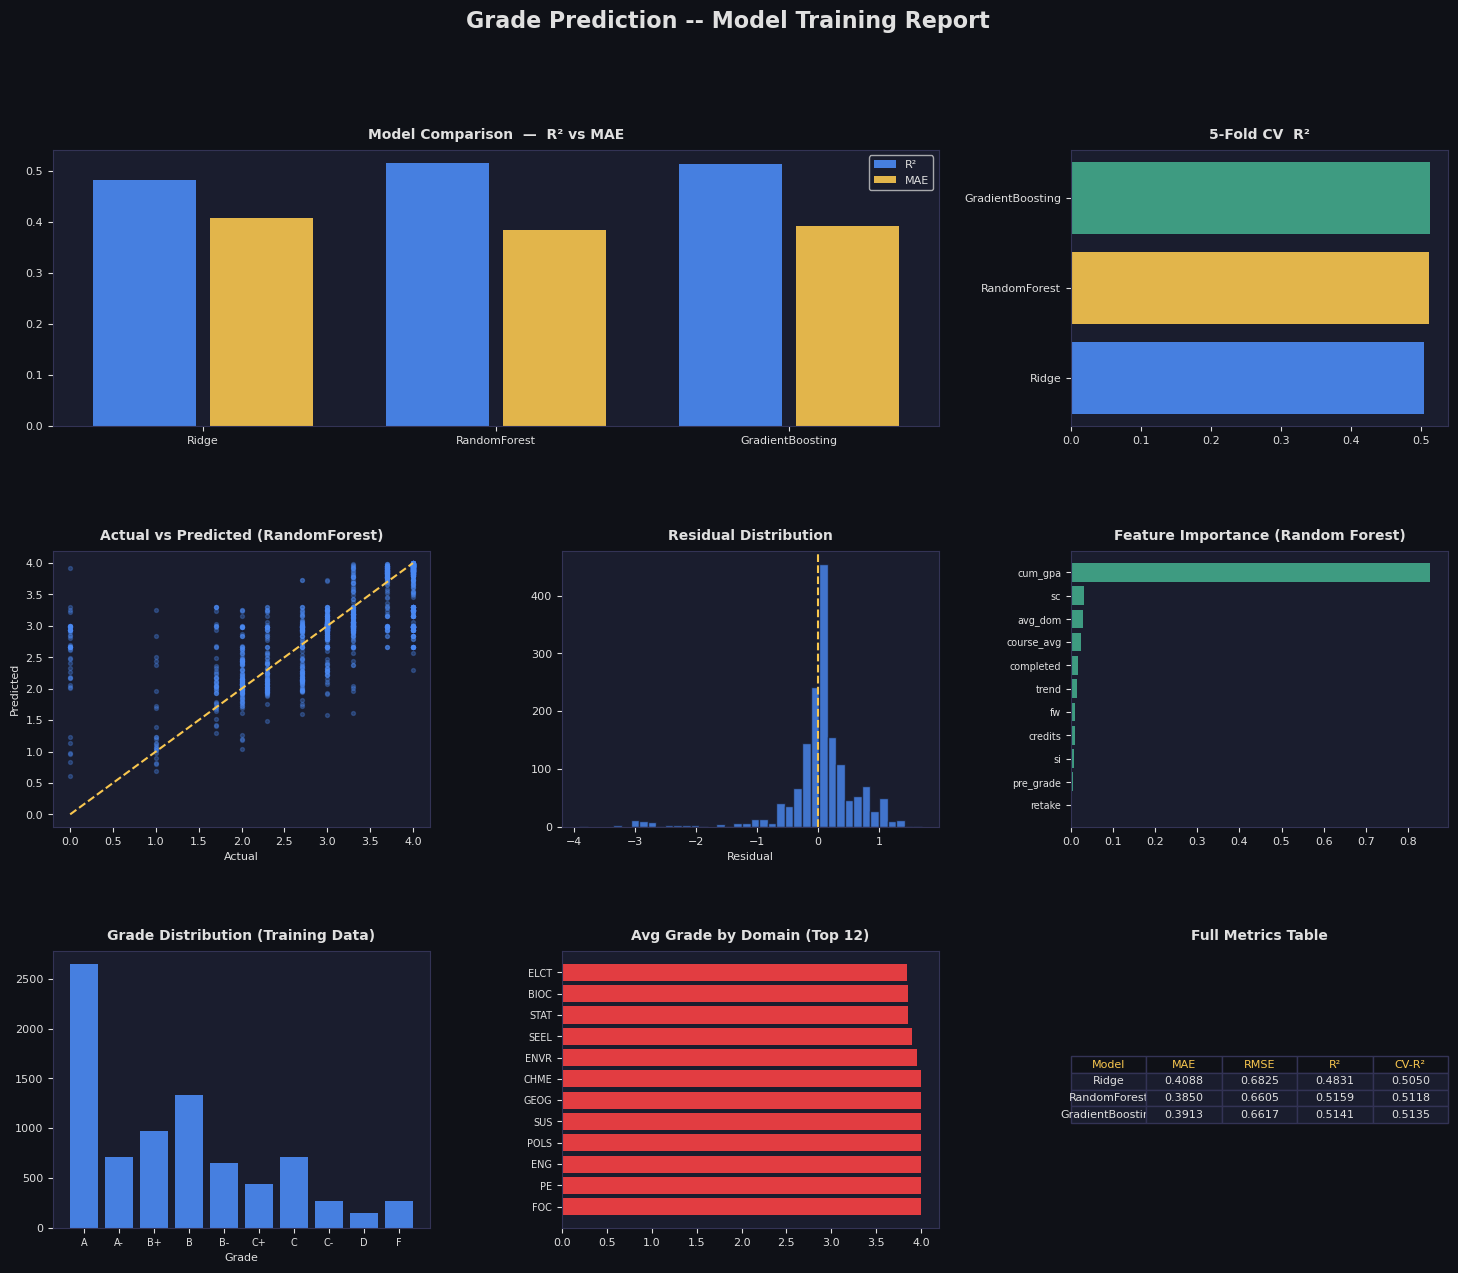

In [6]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import numpy as np

fig = plt.figure(figsize=(18, 14))
fig.patch.set_facecolor("#0f1117")
gs = GridSpec(3, 3, figure=fig, hspace=0.45, wspace=0.35)

DARK, ACCENT, GOLD = "#1a1d2e", "#4c8bf5", "#f9c74f"
TEXT = "#e0e0e0"
PALETTE = ["#4c8bf5", "#f9c74f", "#43aa8b", "#f94144", "#90be6d"]

def ax_style(ax, title):
    ax.set_facecolor(DARK)
    ax.tick_params(colors=TEXT, labelsize=8)
    ax.set_title(title, color=TEXT, fontsize=10, fontweight="bold", pad=8)
    for sp in ax.spines.values(): sp.set_color("#333355")

names = list(res.keys())
r2s   = [res[n]['r2']  for n in names]
maes  = [res[n]['mae'] for n in names]

ax1 = fig.add_subplot(gs[0, :2])
x     = np.arange(len(names))
bars  = ax1.bar(x - 0.2, r2s,  0.35, label="R²",  color=ACCENT, alpha=0.9)
bars2 = ax1.bar(x + 0.2, maes, 0.35, label="MAE", color=GOLD,   alpha=0.9)
ax1.set_xticks(x); ax1.set_xticklabels(names, color=TEXT, fontsize=8)
ax1.legend(facecolor=DARK, labelcolor=TEXT, fontsize=8)
ax_style(ax1, "Model Comparison  —  R² vs MAE")

ax2 = fig.add_subplot(gs[0, 2])
cv_vals = [res[n]["cv"] for n in names]
ax2.barh(names, cv_vals, color=PALETTE[:len(names)], alpha=0.9)
ax_style(ax2, "5-Fold CV  R²")

ax3 = fig.add_subplot(gs[1, 0])
preds_best = best["preds"]
ax3.scatter(yte, preds_best, alpha=0.3, s=8, color=ACCENT)
mn, mx = yte.min(), yte.max()
ax3.plot([mn,mx],[mn,mx], color=GOLD, lw=1.5, linestyle="--")
ax3.set_xlabel("Actual", color=TEXT, fontsize=8)
ax3.set_ylabel("Predicted", color=TEXT, fontsize=8)
ax_style(ax3, f"Actual vs Predicted ({best_nm})")

ax4 = fig.add_subplot(gs[1, 1])
residuals = yte.values - preds_best
ax4.hist(residuals, bins=40, color=ACCENT, alpha=0.8, edgecolor=DARK)
ax4.axvline(0, color=GOLD, lw=1.5, linestyle="--")
ax4.set_xlabel("Residual", color=TEXT, fontsize=8)
ax_style(ax4, "Residual Distribution")

ax5 = fig.add_subplot(gs[1, 2])
rf_model = res["RandomForest"]["model"].named_steps["m"]
imp = rf_model.feature_importances_
idx = np.argsort(imp)
ax5.barh([COLS[i] for i in idx], imp[idx], color=PALETTE[2], alpha=0.9)
ax_style(ax5, "Feature Importance (Random Forest)")
ax5.tick_params(axis='y', labelsize=7)

ax6 = fig.add_subplot(gs[2, 0])
letters = fd["letter"].value_counts()
order   = ["A+","A","A-","B+","B","B-","C+","C","C-","D+","D","D-","F"]
letters = letters.reindex([g for g in order if g in letters.index])
ax6.bar(letters.index, letters.values, color=ACCENT, alpha=0.9)
ax6.set_xlabel("Grade", color=TEXT, fontsize=8)
ax_style(ax6, "Grade Distribution (Training Data)")
ax6.tick_params(axis='x', labelsize=7)

ax7 = fig.add_subplot(gs[2, 1])
dom_avg = fd.groupby("dom")["target"].mean().sort_values(ascending=False).head(12)
ax7.barh(dom_avg.index, dom_avg.values, color=PALETTE[3], alpha=0.9)
ax_style(ax7, "Avg Grade by Domain (Top 12)")
ax7.tick_params(axis='y', labelsize=7)

ax8 = fig.add_subplot(gs[2, 2])
ax8.axis("off")
ax8.set_facecolor(DARK)
rows = [[n, f"{res[n]['mae']:.4f}", f"{res[n]['rmse']:.4f}",
         f"{res[n]['r2']:.4f}", f"{res[n]['cv']:.4f}"] for n in names]
tbl  = ax8.table(cellText=rows, colLabels=["Model","MAE","RMSE","R²","CV-R²"],
                  loc="center", cellLoc="center")
tbl.auto_set_font_size(False); tbl.set_fontsize(8)
for (r, c), cell in tbl.get_celld().items():
    cell.set_facecolor("#0f1117" if r == 0 else DARK)
    cell.set_text_props(color=GOLD if r == 0 else TEXT)
    cell.set_edgecolor("#333355")
ax8.set_title("Full Metrics Table", color=TEXT, fontsize=10, fontweight="bold", pad=8)

fig.suptitle("Grade Prediction -- Model Training Report", color=TEXT, fontsize=16, fontweight="bold", y=0.98)

plt.show()

###  Inference Example

In [7]:
def predict(student_json: dict) -> dict:
    """Run a grade prediction for a new student input."""
    with open(model_path, "rb") as f:
        bundle = pickle.load(f)
    model = bundle["model"]
    cols  = bundle["cols"]

    history = student_json.get("transcript_history", [])
    prereqs_for_target = []  # In a full app, pull this from the catalog

    hist_df = pd.DataFrame([
        {"course_id": h["course"], "grade_num": to_gpa(h["grade"]),
         "sem_idx": i, "domain": dom(h["course"])}
        for i, h in enumerate(history)
    ])

    tgt_dom  = dom(student_json["target_course"])
    dom_hist = hist_df[hist_df["domain"] == tgt_dom]["grade_num"].dropna()
    avg_dom  = dom_hist.mean() if len(dom_hist) > 0 else 2.5

    pq_hist  = hist_df[hist_df["course_id"].isin(prereqs_for_target)]["grade_num"].dropna()
    pq_grade = pq_hist.mean() if len(pq_hist) > 0 else np.nan

    hist_grades = hist_df["grade_num"].dropna()
    if len(hist_grades) >= 2:
        xs = np.arange(len(hist_grades))
        trend = np.polyfit(xs, hist_grades.values, 1)[0]
    else:
        trend = 0.0

    row = pd.DataFrame([{
        "course_avg":            2.5,
        "credits":               3,
        "avg_dom":               avg_dom,
        "pre_grade":             pq_grade,
        "cum_gpa":               student_json.get("cumulative_gpa", 2.5),
        "sc":                    student_json.get("current_semester_credit_load", 15),
        "fw":                    0,
        "trend":                 trend,
        "completed":             len(hist_df),
        "retake":                0,
        "si":                    len(set(h["semester"] for h in history))
    }])

    pred_num = float(model.predict(row[cols])[0])
    pred_num = np.clip(pred_num, 0.0, 4.3)
    pred_let = to_letter(pred_num)
    conf     = min(0.95, 0.5 + bundle["r2"] * 0.5)

    trend_label = "improving" if trend > 0.05 else ("declining" if trend < -0.05 else "stable")
    prereq_str  = f"{to_letter(pq_grade)} in prereq" if not np.isnan(pq_grade) else "No prereq data"
    dom_str     = f"{avg_dom:.2f} avg in {tgt_dom} courses"

    return {
        "student_id":       student_json.get("student_id"),
        "target_course":    student_json["target_course"],
        "predicted_grade":  pred_let,
        "predicted_numeric":round(pred_num, 2),
        "confidence":       round(conf, 2),
        "reasoning": {
            "prerequisite_grade": prereq_str,
            "domain_avg":         dom_str,
            "gpa_trend":          trend_label
        },
        "recommendation": (
            f"Student is expected to perform well. "
            f"GPA trend is {trend_label}. "
            f"Average in {tgt_dom} domain: {avg_dom:.2f}."
        )
    }

# Run a test case:
demo = {
    "student_id": "STU-2021-0042",
    "target_course": "MATH301",
    "transcript_history": [
        {"course": "MATH101", "grade": "A",  "semester": "Fall 2021"},
        {"course": "MATH201", "grade": "B+", "semester": "Spring 2022"},
        {"course": "PHYS101", "grade": "B",  "semester": "Fall 2021"}
    ],
    "cumulative_gpa": 3.2,
    "current_semester_credit_load": 15
}

print(json.dumps(predict(demo), indent=2))


{
  "student_id": "STU-2021-0042",
  "target_course": "MATH301",
  "predicted_grade": "B",
  "predicted_numeric": 3.06,
  "confidence": 0.76,
  "reasoning": {
    "prerequisite_grade": "No prereq data",
    "domain_avg": "3.65 avg in MATH courses",
    "gpa_trend": "declining"
  },
  "recommendation": "Student is expected to perform well. GPA trend is declining. Average in MATH domain: 3.65."
}
